# 01 – Exploration du dataset C-MAPSS (FD001)

Objectif : comprendre la structure des données, repérer les capteurs utiles et visualiser la dégradation des moteurs.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # pour importer src/

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data.load import load_cmapss, add_rul, constant_columns, SENSOR_COLS, SETTING_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Chargement

In [2]:
train, test, rul_test = load_cmapss("FD001")
print("train :", train.shape, "| moteurs :", train.unit.nunique())
print("test  :", test.shape, "| moteurs :", test.unit.nunique())
print("RUL test :", rul_test.shape)
train.head()

train : (20631, 26) | moteurs : 100
test  : (13096, 26) | moteurs : 100
RUL test : (100,)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


## 2. Durée de vie des moteurs

Combien de cycles chaque moteur tient-il avant la panne ?

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


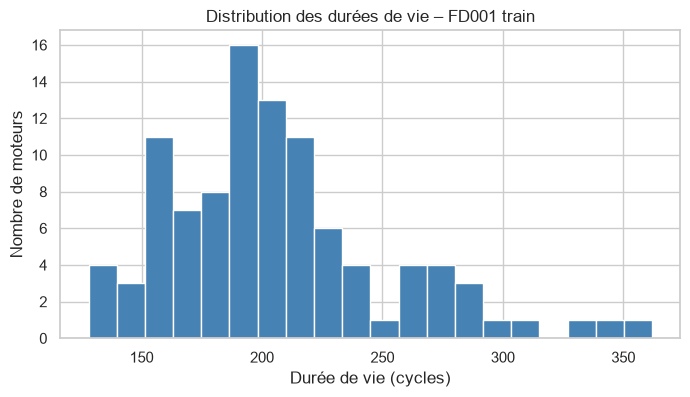

In [4]:
lifetimes = train.groupby("unit")["cycle"].max()
print(lifetimes.describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lifetimes, bins=20, color="steelblue", edgecolor="white")
ax.set(xlabel="Durée de vie (cycles)", ylabel="Nombre de moteurs", title="Distribution des durées de vie – FD001 train")
plt.show()

## 3. Capteurs constants

Un capteur qui ne varie pas n'apporte aucune information : on le supprimera.

In [5]:
const = constant_columns(train)
print("Colonnes constantes :", const)

std = train[SETTING_COLS + SENSOR_COLS].std().sort_values()
std.head(10)

Colonnes constantes : ['op3', 's1', 's5', 's10', 's16', 's18', 's19']


s1     0.000000e+00
op3    0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
dtype: float64

## 4. Évolution des capteurs jusqu'à la panne

On aligne les moteurs sur la panne (axe x = RUL brute, 0 = panne) pour voir les tendances de dégradation.

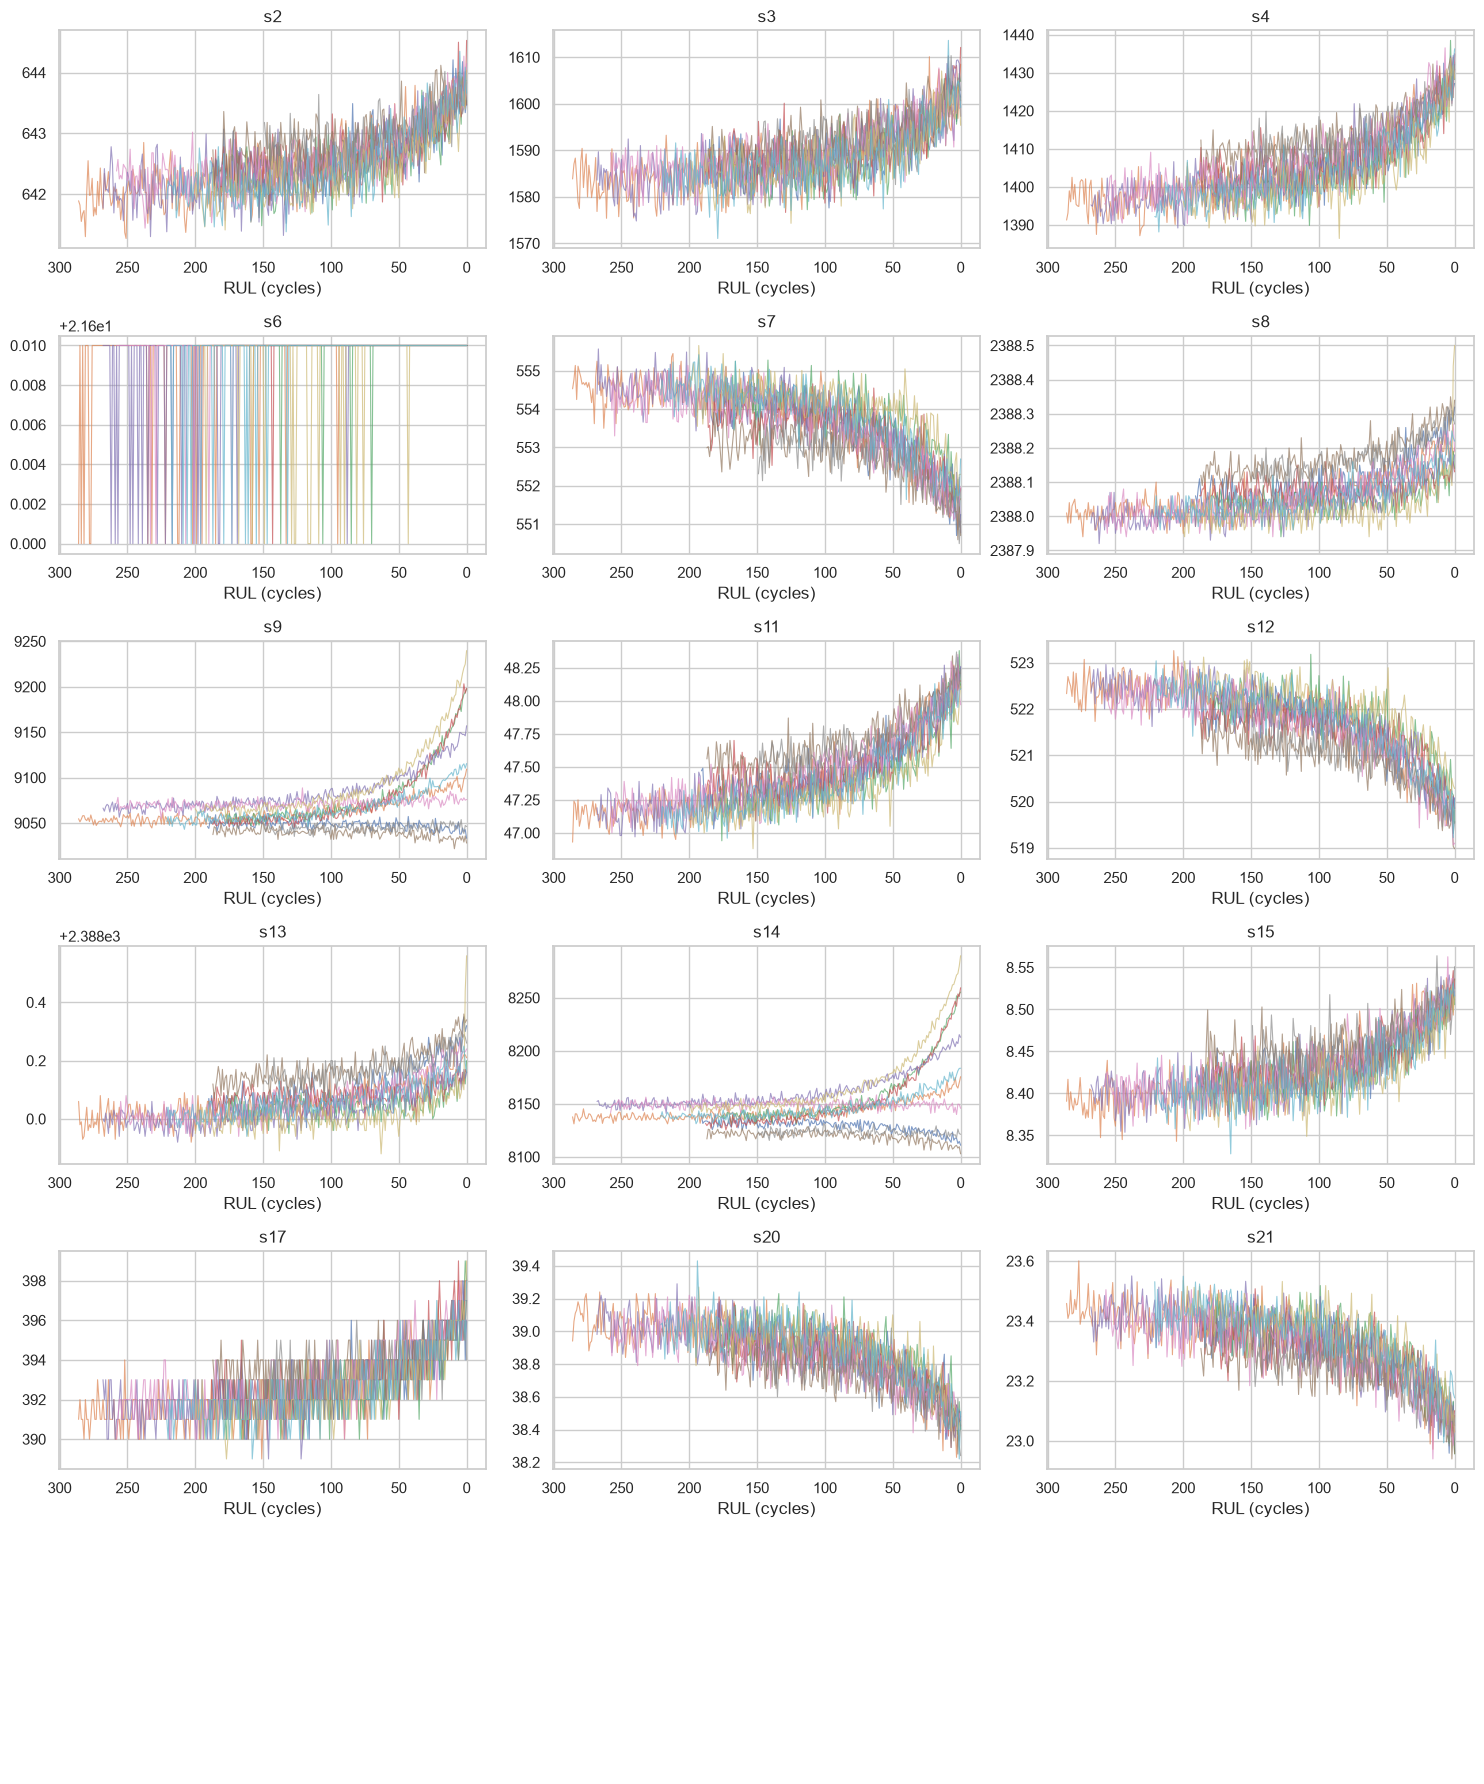

In [6]:
df = add_rul(train, clip=None)
useful = [c for c in SENSOR_COLS if c not in const]
units = df.unit.unique()[:10]  # 10 moteurs

fig, axes = plt.subplots(len(useful) // 3 + 1, 3, figsize=(15, 3 * (len(useful) // 3 + 1)))
for ax, s in zip(axes.flat, useful):
    for u in units:
        d = df[df.unit == u]
        ax.plot(d["RUL"], d[s], lw=0.8, alpha=0.7)
    ax.set_title(s)
    ax.invert_xaxis()  # la panne à droite
    ax.set_xlabel("RUL (cycles)")
for ax in axes.flat[len(useful):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Corrélation des capteurs avec la RUL

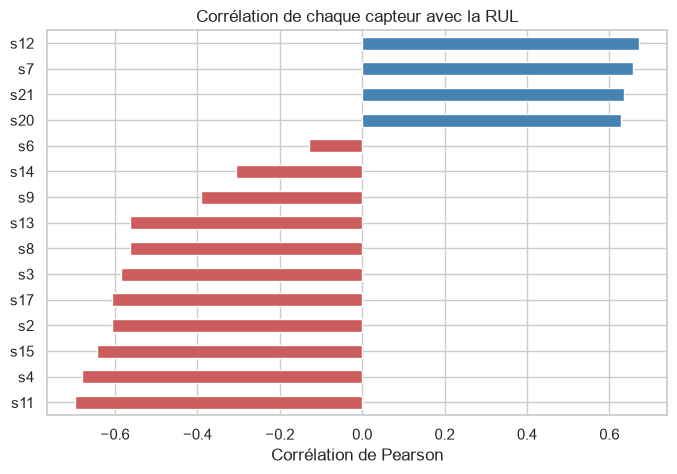

In [7]:
corr = df[useful + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
corr.plot.barh(ax=ax, color=["indianred" if v < 0 else "steelblue" for v in corr])
ax.set(title="Corrélation de chaque capteur avec la RUL", xlabel="Corrélation de Pearson")
plt.show()

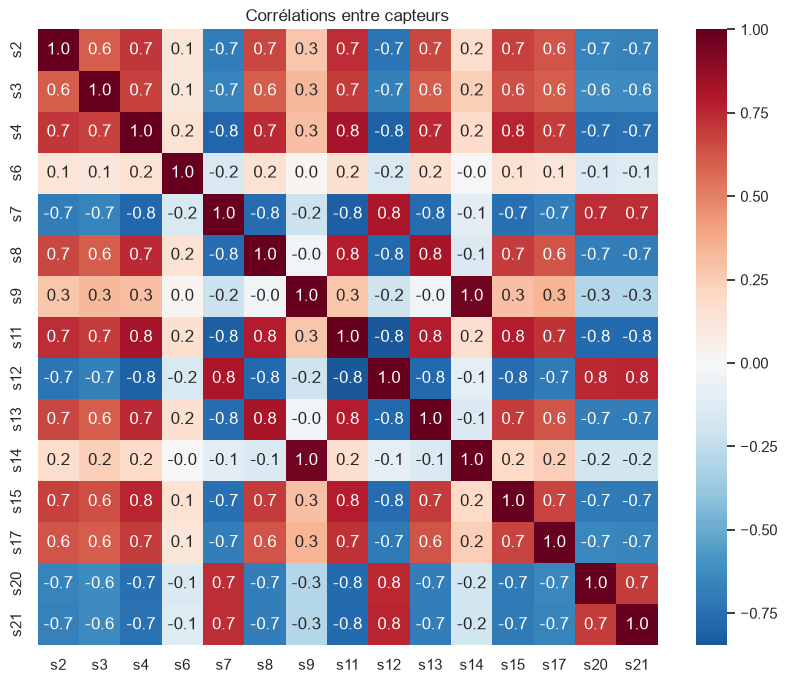

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[useful].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax)
ax.set_title("Corrélations entre capteurs")
plt.show()

## 6. Le jeu de test

Les trajectoires de test s'arrêtent avant la panne. La vraie RUL au dernier cycle est dans `RUL_FD001.txt`.

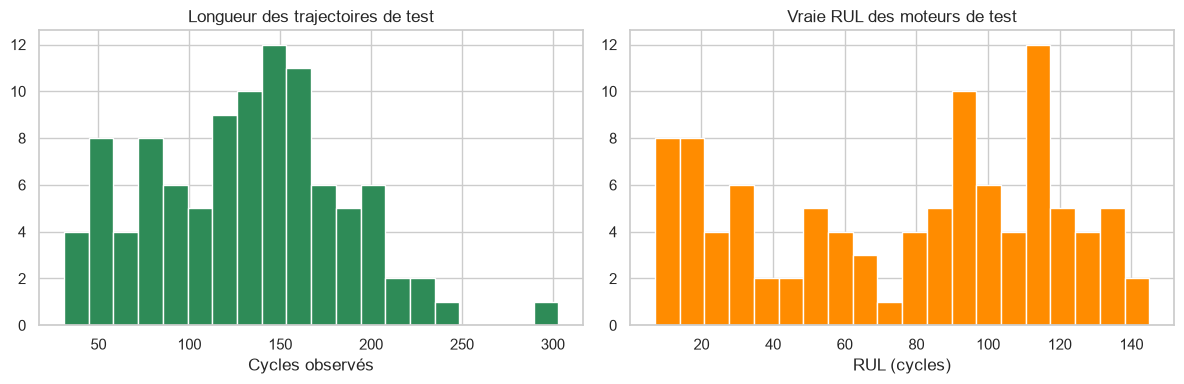

In [9]:
test_len = test.groupby("unit")["cycle"].max()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(test_len, bins=20, color="seagreen", edgecolor="white")
axes[0].set(title="Longueur des trajectoires de test", xlabel="Cycles observés")
axes[1].hist(rul_test, bins=20, color="darkorange", edgecolor="white")
axes[1].set(title="Vraie RUL des moteurs de test", xlabel="RUL (cycles)")
plt.tight_layout()
plt.show()

## 7. Conclusions

- **Structure** : 100 moteurs suivis jusqu'à la panne (20 631 lignes). Durée de vie entre 128 et 362 cycles, 206 en moyenne (médiane 199).
- **Colonnes supprimées** : op3, s1, s5, s10, s16, s18, s19 (constantes), s6 (ne prend que 2 valeurs : bruit de quantification), op1 et op2 (une seule condition de vol dans FD001, leurs variations sont du bruit).
- **14 capteurs retenus** : s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21.
- **Dégradation non linéaire** : les capteurs restent plats en début de vie puis s'emballent dans les 50 à 100 derniers cycles → justifie de plafonner la RUL.
- **Capteurs les plus informatifs** : s11, s4, s12, s7, s15, s21, s20 (corrélation ±0,65 à 0,70 avec la RUL). Certains montent à l'approche de la panne (s2, s4, s11, s15), d'autres descendent (s7, s12, s20, s21).
- **Redondance** : s9 et s14 sont corrélés à 1,0 ; leur comportement dépend du moteur.
- **Bruit important** sur tous les capteurs → moyennes glissantes à prévoir.
- **Test** : trajectoires coupées entre 31 et 303 cycles, vraie RUL entre 7 et 145. Les moteurs observés peu longtemps seront les plus difficiles.